# Check whether the times after 2026-11-01 follow the clock

**Objective.** Find out whether the times in the file moved back one hour when clocks changed on 2026-11-01. Notebook load_and_check_readings showed that every row has the offset `-05:00`, even after that date. This notebook measures the effect and changes nothing in the data.

The approach is the same as before: Knuth (1984, *Computer Journal* 27:97-111) and Rule et al. (2019, *PLoS Computational Biology* 15:e1007007).

## Step 1. Read the file with a function

In [1]:
source("src/read_glucose.R")
source("src/shift_correlation.R")
glucose <- read_glucose("../data/lingo-glucose-2026-09-27-to-2026-11-17.csv")
head(glucose[, c("time", "glucose", "out_of_range")])

                 time glucose out_of_range
1 2026-09-27 08:17:00     138        FALSE
2 2026-09-27 08:22:00     131        FALSE
3 2026-09-27 08:27:00     127        FALSE
4 2026-09-27 08:32:00     142        FALSE
5 2026-09-27 08:37:00     135        FALSE
6 2026-09-27 08:42:00     131        FALSE


**Explanation**

* `source("src/read_glucose.R")` runs the file `read_glucose.R` in the `src` folder. That file defines a function named `read_glucose`. A function is a set of steps kept under a name so that every notebook can use it without copying the steps.
* `read_glucose(path)` repeats the steps of the first notebook: it reads the file, marks the "Out of range" rows, turns the glucose column into numbers, and sets the "Out of range" readings to 54. Their true value is below 55, so 54 is the highest value they can have.
* `source("src/shift_correlation.R")` loads a second function, used in Step 5.
* The time is read exactly as written in the file, with the `-05:00` part ignored. The label `tz = "UTC"` inside the function only stops R from changing the hour to the time zone of this computer.
* `glucose[, c("time", "glucose", "out_of_range")]` keeps all rows and only these three columns. `head(...)` shows the first 6 rows.

## Step 2. Label each reading with its half hour of the day and its period

In [2]:
hour   <- as.integer(format(glucose$time, "%H"))
minute <- as.integer(format(glucose$time, "%M"))
glucose$slot <- hour * 2 + minute %/% 30
glucose$period <- ifelse(as.Date(glucose$time) < as.Date("2026-11-01"),
                         "before", "after")
table(glucose$period)


 after before 
  4188   9370 


**Explanation**

* `format(glucose$time, "%H")` takes the hour from each time, and `"%M"` takes the minute. `as.integer(...)` turns that text into a whole number.
* `hour * 2 + minute %/% 30` gives each reading a half-hour number from 0 to 47. The sign `%/%` divides and drops the remainder. For example, 08:17 is `8 * 2 + 17 %/% 30`, which is 16 + 0, so slot 16. Slot 0 is midnight to 00:29, and slot 47 is 23:30 to 23:59.
* `ifelse(test, a, b)` gives `a` where the test is true and `b` where it is false. Here a reading is "before" if its date is earlier than 2026-11-01, and "after" otherwise. Clocks changed at 2 am on that date, so the label is exact to within the first two hours of the day.
* `table(...)` counts the readings in each period.

**Result.** There are 9,370 readings before 2026-11-01 and 4,188 after.

## Step 3. Average glucose in each half hour, before and after

In [3]:
profile <- tapply(glucose$glucose,
                  list(glucose$slot, glucose$period), mean)
head(round(profile, 1))

  after before
0  87.7   72.6
1  83.6   73.0
2  80.5   73.0
3  76.5   72.2
4  73.5   73.1
5  77.0   71.1


**Explanation**

* `tapply(values, groups, mean)` splits the values into groups and takes the mean of each group.
* `list(glucose$slot, glucose$period)` makes the groups: one for every pair of half-hour slot and period. The result is a table with 48 rows (slots) and 2 columns (after, before).
* `round(profile, 1)` rounds to one decimal place. `head(...)` shows the first 6 rows, which are the half hours from midnight to 02:59.
* We call this table a daily profile: the average glucose in each half hour of the day.

## Step 4. Plot the two profiles

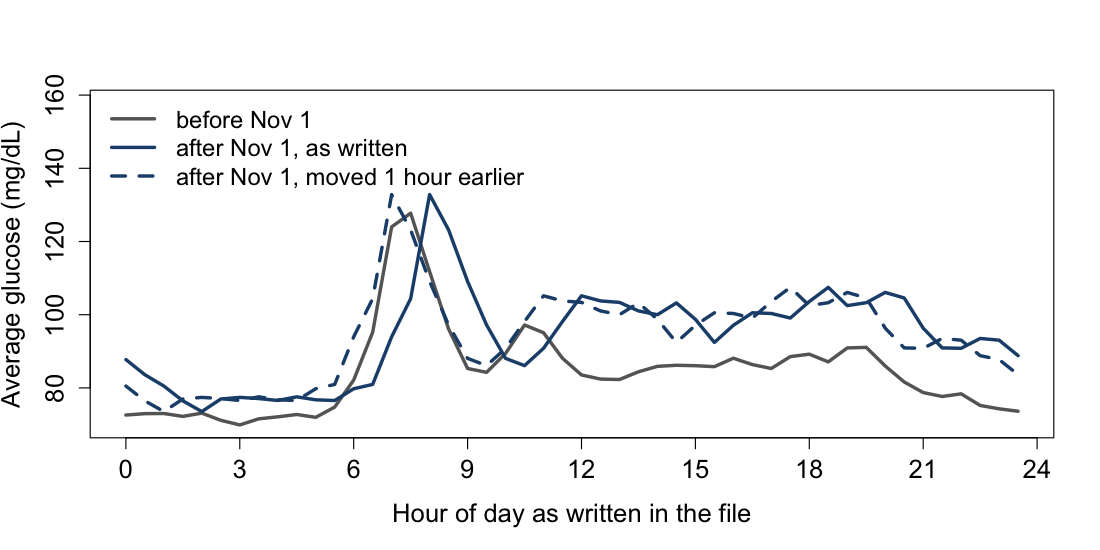

In [4]:
hours <- (0:47) / 2
plot(hours, profile[, "before"], type = "l", lwd = 3, col = "gray40",
     ylim = c(min(profile), max(profile) + 25), xaxt = "n",
     xlab = "Hour of day as written in the file",
     ylab = "Average glucose (mg/dL)", cex.lab = 1.4, cex.axis = 1.4)
axis(1, at = seq(0, 24, 3), cex.axis = 1.4)
lines(hours, profile[, "after"], lwd = 3, col = "#1f4e79")
lines(hours, profile[(0:47 + 2) %% 48 + 1, "after"], lwd = 3,
      col = "#1f4e79", lty = 2)
legend("topleft", bty = "n", lwd = 3, lty = c(1, 1, 2),
       col = c("gray40", "#1f4e79", "#1f4e79"), cex = 1.3,
       legend = c("before Nov 1", "after Nov 1, as written",
                  "after Nov 1, moved 1 hour earlier"))

**Explanation**

* `hours <- (0:47) / 2` turns the slot numbers 0 to 47 into hours 0 to 23.5, for the horizontal axis.
* `plot(x, y, type = "l", ...)` draws a line. `lwd` is the line width, `col` the colour, `ylim` the range of the vertical axis (here from the lowest value to 25 above the highest, so the legend has room), and `xaxt = "n"` leaves out the default horizontal axis so that `axis(1, at = seq(0, 24, 3))` can draw labels every 3 hours. `cex.lab` and `cex.axis` make the text larger.
* The first line, gray, is the profile before 2026-11-01. `lines(...)` adds the profile after 2026-11-01, in blue.
* The dashed blue line is the same profile with every value moved 1 hour (2 slots) earlier. In `profile[(0:47 + 2) %% 48 + 1, "after"]`, the sign `%%` is the remainder after dividing, which makes the day wrap around so that the first hour is placed at the end.
* `legend(...)` names the three lines.

## Step 5. Measure which shift matches best

In [5]:
shifts <- -3:3
after_vs_before <- shift_correlation(profile[, "before"], profile[, "after"], shifts)

before <- glucose[glucose$period == "before", ]
half <- ifelse(as.Date(before$time) < as.Date("2026-10-20"), "first", "second")
halves <- tapply(before$glucose, list(before$slot, half), mean)
first_vs_second <- shift_correlation(halves[, "first"], halves[, "second"], shifts)

round(rbind(hours_earlier = shifts,
            after_vs_before = after_vs_before,
            first_vs_second_half_before = first_vs_second), 2)

                             [,1]  [,2]  [,3] [,4] [,5] [,6] [,7]
hours_earlier               -3.00 -2.00 -1.00 0.00 1.00 2.00 3.00
after_vs_before             -0.10  0.02  0.14 0.57 0.88 0.49 0.16
first_vs_second_half_before  0.07  0.11  0.57 0.94 0.48 0.11 0.16


**Explanation**

* The correlation between two profiles is a number from -1 to 1. It is 1 when the two curves rise and fall together, 0 when they are unrelated. It does not depend on the average level, which matters because the average glucose is higher after 2026-11-01.
* `shift_correlation(fixed, moving, hours)` moves the second profile earlier by each number of hours in `shifts`, and gives the correlation with the first profile each time. A shift of 0 is the profile as written. A negative number moves it later.
* `after_vs_before` compares the profile after 2026-11-01 with the profile before.
* The second block is a comparison where we know no clock change happened. We split the readings before 2026-11-01 into two parts, up to 2026-10-19 and from 2026-10-20, and compare their profiles. This shows how well two stretches of the same clock agree with each other.
* `rbind(...)` stacks the three rows into one table, and `round(..., 2)` rounds to 2 decimal places.

**Result.** The profile after 2026-11-01 matches the earlier profile best when it is moved 1 hour earlier (correlation 0.88). As written, with no move, the correlation is 0.57. Two stretches before 2026-11-01 match each other best with no move (0.94), and moving them by 1 hour lowers the correlation to 0.57 or 0.48.

This is what we would see if the times in the file stayed on `-05:00` after clocks changed. It is indirect evidence: it relies on the daily routine being the same before and after. A reading at a known clock time, such as a meal or medicine, would settle it. No times were changed in this notebook.